# 2.2c Comportamiento de los modelos con fotos propias

Los modelos finales de la 2.2 (`resultados/configuracion_final.json`: YOLOv11n y YOLOv11s, 3 semillas cada uno) se aplican a 5 fotos propias tomadas con smartphone, fuera del dataset: otra cámara, otra iluminación y otros granos. El objetivo es ver si el comportamiento observado en `valid` se mantiene en condiciones distintas y, donde falle, explorar los factores asociados.

**Fotos** (`fotos/propias/`, sin metadatos):
- `imgPrueba` e `imgPrueba2`: los mismos 11 granos en dos disposiciones, con los sanos a la izquierda y los defectuosos a la derecha.
- `imgTest3`: 16 granos, sanos y defectuosos mezclados.
- `imgArrugados`: 8 granos arrugados (`Shriveled`); una sola clase.
- `imgMixta`: 15 granos, 7 sanos (grandes) y 8 arrugados (pequeños), mezclados.

**Preprocesamiento:** cada foto pasa por `comun.preprocesar(img, 1280, 'norm')`, el mismo del dataset (lado mayor a 1280 px, normalización fotométrica y relleno hasta un múltiplo de 32). La referencia se lleva a las mismas coordenadas.

**Referencia** (`fotos/propias/referencia/`, formato YOLO, en coordenadas de la foto original):
- **Cajas:** consenso de las detecciones de las 6 corridas finales: la mediana de las cajas que coinciden (IoU ≥ 0.5) en al menos 4 corridas.
- **Clase:** asignada por inspección visual. `Defect` si el grano tiene moho, está partido, arrugado o con manchas; `Healthy` en otro caso.

**Criterios:** como en el diagnóstico (2.2b), con el umbral de conteo de cada modelo y NMS agnóstico a la clase. Un grano está acertado si una predicción lo cubre con IoU ≥ 0.5 y con la clase correcta.

Este análisis no entrena ni cambia los modelos.

In [1]:
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

os.environ['YOLO_VERBOSE'] = 'False'
from ultralytics import YOLO

import comun_oe2 as E

C = E.C
C.estilo()
RAIZ = Path.cwd()
FOTOS = E.FOTOS / 'propias'
SALIDA = RAIZ / 'salida' / '2.2c_fotos_propias'
CFG = E.configuracion('final')
ETIQUETA = {'yolo11n': 'YOLOv11n', 'yolo11s': 'YOLOv11s'}
CLASE = {0: 'Healthy', 1: 'Defect'}
MODELOS = {m: [(s, YOLO(str(p))) for s, p in zip(c['semillas'], c['pesos'])] for m, c in CFG.items()}
S0 = CFG['yolo11s']['semillas'][0]

def cargar_foto(stem):
    # Foto original (BGR), cajas de referencia (x1, y1, x2, y2) en sus coordenadas y clases
    img = cv2.imread(str(FOTOS / f'{stem}.jpeg'))
    H, W = img.shape[:2]
    c, cl = C.leer_yolo(FOTOS / 'referencia' / f'{stem}.txt')
    c = np.array(c, float).reshape(-1, 4)
    return img, np.stack([(c[:, 0] - c[:, 2] / 2) * W, (c[:, 1] - c[:, 3] / 2) * H,
                          (c[:, 0] + c[:, 2] / 2) * W, (c[:, 1] + c[:, 3] / 2) * H], 1), np.array(cl)

def preparar(img, cajas, imgsz=E.IMGSZ, fotometrico='norm'):
    # Preprocesamiento del dataset y referencia en las coordenadas de la imagen preprocesada
    pre, esc, (dx, dy) = C.preprocesar(img, imgsz, fotometrico)
    return pre, cajas * esc + [dx, dy, dx, dy]

def evaluar(img, cajas, clases, modelo, imgsz=E.IMGSZ, fotometrico='norm'):
    # Por semilla: detecciones, sanos y defectuosos acertados y predicciones, sobre la foto preprocesada
    pre, ref = preparar(img, cajas, imgsz, fotometrico)
    filas = []
    for semilla, mod in MODELOS[modelo]:
        r = mod.predict(pre, imgsz=imgsz, conf=CFG[modelo]['conf_conteo'], agnostic_nms=True, verbose=False)[0]
        pb, pc = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)
        pares, _ = E.emparejar(ref, pb)
        ok = np.array([g in pares and pc[pares[g]] == clases[g] for g in range(len(clases))])
        filas.append({'modelo': ETIQUETA[modelo], 'semilla': semilla, 'detecciones': len(pb),
                      'Healthy predichos': int((pc == 0).sum()), 'Defect predichos': int((pc == 1).sum()),
                      'sanos acertados': ok[clases == 0].mean() if (clases == 0).any() else np.nan,
                      'defectuosos acertados': ok[clases == 1].mean() if (clases == 1).any() else np.nan,
                      'no detectados': len(clases) - len(pares),
                      'errores de clase': sum(pc[q] != clases[g] for g, q in pares.items()),
                      'cajas': pb, 'clases': pc})
    return filas, pre, ref

FOTOS_STEMS = ['imgPrueba', 'imgPrueba2', 'imgTest3']
ESCENAS_FOTOS = ['imgArrugados', 'imgMixta']
REF = {s: cargar_foto(s) for s in FOTOS_STEMS + ESCENAS_FOTOS}
display(pd.DataFrame({s: {'tamaño': f'{img.shape[1]} × {img.shape[0]}', 'granos': len(cl),
                          'Healthy': int((cl == 0).sum()), 'Defect': int((cl == 1).sum())}
                      for s, (img, _, cl) in REF.items()}).T)

,tamaño,granos,Healthy,Defect
imgPrueba,1496 × 1200,11,6,5
imgPrueba2,1463 × 1200,11,6,5
imgTest3,1280 × 960,16,8,8
imgArrugados,960 × 1280,8,0,8
imgMixta,960 × 1280,15,7,8


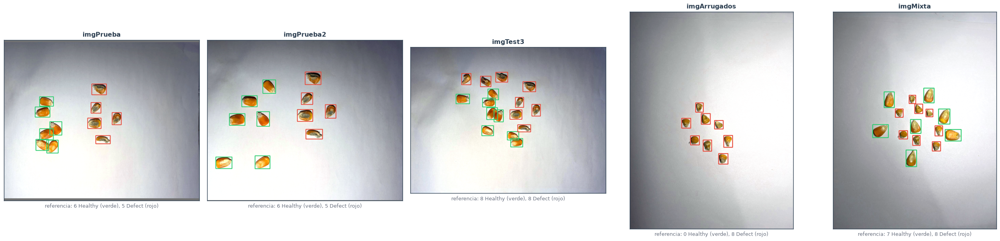

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(26, 6.2))
for ax, (s, (img, cajas, cl)) in zip(axes, REF.items()):
    pre, ref = preparar(img, cajas)
    vista = E.dibujar(E.dibujar(cv2.cvtColor(pre, cv2.COLOR_BGR2RGB), ref[cl == 0], E.CAJA_OK, 4), ref[cl == 1], E.CAJA_MAL, 4)
    E.mostrar(ax, vista, s, f'referencia: {(cl == 0).sum()} Healthy (verde), {(cl == 1).sum()} Defect (rojo)')
C.guardar(SALIDA, 'referencia.png')

## 1. Diferencias con `Data_final`

Características de las fotos preprocesadas frente a las imágenes de entrenamiento, normalizadas igual:
- **Calidad JPEG** de la foto original, estimada a partir de su tabla de cuantización.
- **Lado del grano** a 1280 px, la escala a la que trabaja la red.
- **Color:** tono (H), saturación (S) y brillo (V) medios de los granos, y brillo del papel.

In [3]:
TABLA_IJG = np.array([16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
                      14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
                      49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99])

def calidad_jpeg(ruta):
    # Calidad aproximada (escala IJG) a partir de la tabla de cuantización de luminancia
    t = np.array(Image.open(ruta).quantization[0])
    s = np.mean(t / TABLA_IJG) * 100
    return round((200 - s) / 2 if s <= 100 else 5000 / s)

def rasgos(img, cajas):
    # Lado del grano y color medio de granos y papel, sobre una imagen ya preprocesada (BGR)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(float)
    m = np.zeros(img.shape[:2], bool)
    for x1, y1, x2, y2 in cajas.astype(int):
        m[max(y1, 0):y2, max(x1, 0):x2] = True
    lado = np.median(np.sqrt((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1])))
    return {'lado del grano (px)': lado, 'H grano': hsv[m][:, 0].mean(), 'S grano': hsv[m][:, 1].mean(),
            'V grano': hsv[m][:, 2].mean(), 'V papel': hsv[~m][:, 2].mean()}

ent = []
for p in sorted((E.FINAL / 'train' / 'images').glob('*.jpg')):
    img, cajas, _, _ = E.cargar(p.stem, 'train')
    ent.append(rasgos(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), cajas))
ent = pd.DataFrame(ent)
originales = sorted(E._DATA_CORR.glob('*/images/*.jpg'))
calidad_ent = [calidad_jpeg(p) for p in originales[::10]]
filas = {'Data_final train (p5–p95)': {**{k: f'{ent[k].quantile(0.05):.0f}–{ent[k].quantile(0.95):.0f}' for k in ent},
                                       'calidad JPEG': f'{min(calidad_ent)}–{max(calidad_ent)} (originales)'}}
for s, (img, cajas, _) in REF.items():
    pre, ref = preparar(img, cajas)
    filas[s] = {**{k: f'{v:.0f}' for k, v in rasgos(pre, ref).items()},
                'calidad JPEG': f'{calidad_jpeg(FOTOS / f"{s}.jpeg")} ({img.shape[1]} × {img.shape[0]} px)'}
display(pd.DataFrame(filas).T)

,lado del grano (px),H grano,S grano,V grano,V papel,calidad JPEG
Data_final train (p5–p95),25–82,23–44,74–163,143–218,190–204,75–75 (originales)
imgPrueba,78,26,122,201,193,85 (1496 × 1200 px)
imgPrueba2,89,29,119,190,195,85 (1463 × 1200 px)
imgTest3,70,30,118,186,197,75 (1280 × 960 px)
imgArrugados,56,24,106,185,196,75 (960 × 1280 px)
imgMixta,52,23,114,197,196,75 (960 × 1280 px)


## 2. Conteo y clasificación

Para cada foto, modelo y semilla: detecciones, granos predichos de cada clase y fracción de sanos y defectuosos acertados.

In [4]:
res, VISTA = [], {}
for s in FOTOS_STEMS:
    img, cajas, cl = REF[s]
    for m in MODELOS:
        filas, pre, ref = evaluar(img, cajas, cl, m)
        VISTA[s] = (pre, ref)
        res += [dict(f, foto=s, granos=len(cl), sanos=int((cl == 0).sum()), defectuosos=int((cl == 1).sum())) for f in filas]
res = pd.DataFrame(res)
cols = ['granos', 'detecciones', 'sanos', 'Healthy predichos', 'defectuosos', 'Defect predichos', 'sanos acertados', 'defectuosos acertados']
display(res.set_index(['foto', 'modelo', 'semilla'])[cols].round(2))
display(res.groupby(['foto', 'modelo'], sort=False)[['sanos acertados', 'defectuosos acertados']].mean().round(3))

granos  detecciones  sanos  Healthy predichos  \
foto       modelo   semilla                                                  
imgPrueba  YOLOv11n 42           11           11      6                  6   
                    7            11           11      6                  6   
                    28           11           11      6                  6   
           YOLOv11s 42           11           11      6                  2   
                    7            11           11      6                  6   
                    28           11           11      6                  6   
imgPrueba2 YOLOv11n 42           11           11      6                  6   
                    7            11           11      6                  6   
                    28           11           11      6                  6   
           YOLOv11s 42           11           11      6                  3   
                    7            11           11      6                  6   
                    28           11           11      6                  6   
imgTest3   YOLOv11n 42           16           15      8                  3   
                    7            16           16      8                  1   
                    28           16           16      8                  1   
           YOLOv11s 42           16           16      8                  0   
                    7            16           16      8                  3   
                    28           16           16      8                  0   

                             defectuosos  Defect predichos  sanos acertados  \
foto       modelo   semilla                                                   
imgPrueba  YOLOv11n 42                 5                 5             1.00   
                    7                  5                 5             1.00   
                    28                 5                 5             1.00   
           YOLOv11s 42                 5                 9             0.33   
                    7                  5                 5             1.00   
                    28                 5                 5             1.00   
imgPrueba2 YOLOv11n 42                 5                 5             1.00   
                    7                  5                 5             1.00   
                    28                 5                 5             1.00   
           YOLOv11s 42                 5                 8             0.50   
                    7                  5                 5             1.00   
                    28                 5                 5             1.00   
imgTest3   YOLOv11n 42                 8                12             0.38   
                    7                  8                15             0.12   
                    28                 8                15             0.12   
           YOLOv11s 42                 8                16             0.00   
                    7                  8                13             0.38   
                    28                 8                16             0.00   

                             defectuosos acertados  
foto       modelo   semilla                         
imgPrueba  YOLOv11n 42                         1.0  
                    7                          1.0  
                    28                         1.0  
           YOLOv11s 42                         1.0  
                    7                          1.0  
                    28                         1.0  
imgPrueba2 YOLOv11n 42                         1.0  
                    7                          1.0  
                    28                         1.0  
           YOLOv11s 42                         1.0  
                    7                          1.0  
                    28                         1.0  
imgTest3   YOLOv11n 42                         1.0  
                    7                          1.0  
                    28                 

sanos acertados  defectuosos acertados
foto       modelo                                          
imgPrueba  YOLOv11n            1.000                    1.0
           YOLOv11s            0.778                    1.0
imgPrueba2 YOLOv11n            1.000                    1.0
           YOLOv11s            0.833                    1.0
imgTest3   YOLOv11n            0.208                    1.0
           YOLOv11s            0.125                    1.0

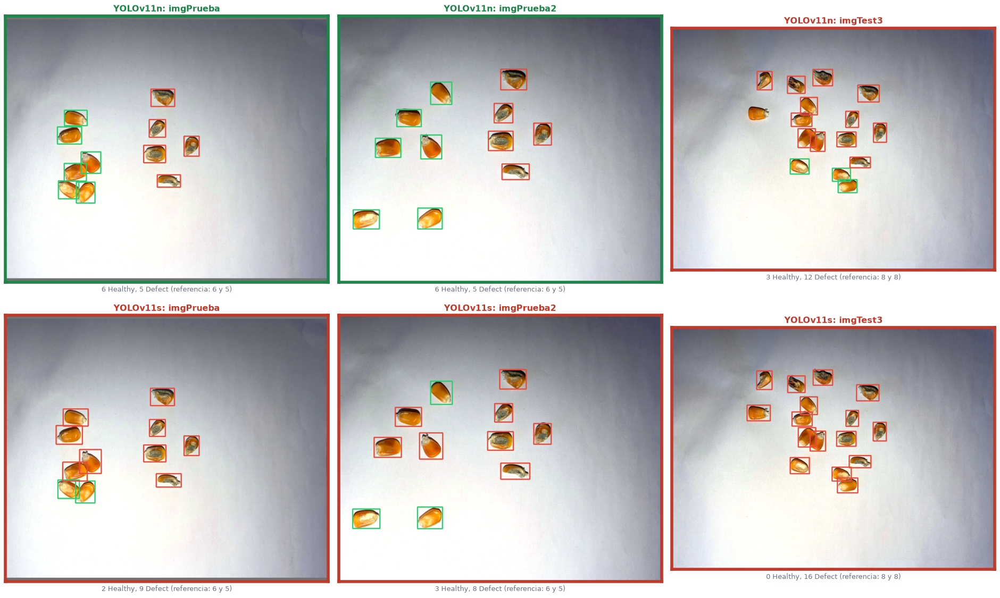

In [5]:
# Predicciones de cada modelo (primera semilla): verde Healthy, rojo Defect
fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
for fila, m in zip(axes, ETIQUETA.values()):
    for ax, s in zip(fila, FOTOS_STEMS):
        f = res[(res.foto == s) & (res.modelo == m) & (res.semilla == S0)].iloc[0]
        img = cv2.cvtColor(VISTA[s][0], cv2.COLOR_BGR2RGB)
        vista = E.dibujar(E.dibujar(img, f['cajas'][f['clases'] == 0], E.CAJA_OK, 4), f['cajas'][f['clases'] == 1], E.CAJA_MAL, 4)
        bien = f['sanos acertados'] == 1 and f['defectuosos acertados'] == 1
        E.mostrar(ax, vista, f'{m}: {s}', f"{f['Healthy predichos']} Healthy, {f['Defect predichos']} Defect "
                  f"(referencia: {f['sanos']} y {f['defectuosos']})", estado='ok' if bien else 'mal')
C.guardar(SALIDA, 'predicciones.png')

## 3. Exploración de factores

Se prueban, solo con inferencia, los factores que pueden distinguir a `imgTest3` de las otras fotos.

**Pruebas sobre `imgTest3`:**
- **Normalización:** la foto sin la normalización fotométrica (`comun.preprocesar` con `'base'`), para ver qué aporta ese paso.
- **Escala:** preprocesamiento e inferencia a 960, 1600 y 1920 px.
- **Contexto:** se borran de la foto original los granos defectuosos (o los sanos) por *inpainting*, sin tocar los demás, y se evalúan los que quedan.

**Pruebas sobre `imgPrueba`:**
- **Compresión JPEG:** calidad 50 y 30.
- **Desenfoque gaussiano:** σ = 1.5 y 2.5.

In [6]:
def borrar(img, cajas, margen=6):
    m = np.zeros(img.shape[:2], np.uint8)
    for x1, y1, x2, y2 in cajas.astype(int):
        m[max(y1 - margen, 0):y2 + margen, max(x1 - margen, 0):x2 + margen] = 255
    return cv2.inpaint(img, m, 7, cv2.INPAINT_TELEA)

def jpeg(img, q):
    return cv2.imdecode(cv2.imencode('.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_COLOR)

def prueba(stem, variantes):
    img, cajas, cl = REF[stem]
    filas = []
    for nombre, (x, imgsz, foto, sub) in variantes.items():
        keep = np.ones(len(cl), bool) if sub is None else (cl == sub)
        for m in MODELOS:
            for f in evaluar(x, cajas[keep], cl[keep], m, imgsz, foto)[0]:
                filas.append({'prueba': nombre, 'modelo': f['modelo'], 'detecciones': f['detecciones'],
                              'sanos acertados': f['sanos acertados'], 'defectuosos acertados': f['defectuosos acertados']})
    return pd.DataFrame(filas).groupby(['prueba', 'modelo'], sort=False).mean().unstack('modelo').round(2)

img3, cajas3, cl3 = REF['imgTest3']
VARIANTES_T3 = {'original': (img3, E.IMGSZ, 'norm', None),
                'sin normalizar': (img3, E.IMGSZ, 'base', None),
                'a 960 px': (img3, 960, 'norm', None), 'a 1600 px': (img3, 1600, 'norm', None), 'a 1920 px': (img3, 1920, 'norm', None),
                'sin defectuosos': (borrar(img3, cajas3[cl3 == 1]), E.IMGSZ, 'norm', 0),
                'sin sanos': (borrar(img3, cajas3[cl3 == 0]), E.IMGSZ, 'norm', 1)}
print('imgTest3 (media de las 3 semillas; con un grupo borrado, solo se evalúan los granos que quedan)')
display(prueba('imgTest3', VARIANTES_T3))

img1 = REF['imgPrueba'][0]
VARIANTES_P1 = {'original': (img1, E.IMGSZ, 'norm', None), 'sin normalizar': (img1, E.IMGSZ, 'base', None),
                'JPEG calidad 50': (jpeg(img1, 50), E.IMGSZ, 'norm', None), 'JPEG calidad 30': (jpeg(img1, 30), E.IMGSZ, 'norm', None),
                'desenfoque σ 1.5': (cv2.GaussianBlur(img1, (0, 0), 1.5), E.IMGSZ, 'norm', None),
                'desenfoque σ 2.5': (cv2.GaussianBlur(img1, (0, 0), 2.5), E.IMGSZ, 'norm', None)}
print('imgPrueba')
display(prueba('imgPrueba', VARIANTES_P1))

imgTest3 (media de las 3 semillas; con un grupo borrado, solo se evalúan los granos que quedan)


detecciones          sanos acertados           \
modelo             YOLOv11n YOLOv11s        YOLOv11n YOLOv11s   
prueba                                                          
original              15.67    16.00            0.21     0.12   
sin normalizar        15.67    15.00            0.12     0.04   
a 960 px              16.00    16.00            0.12     0.38   
a 1600 px             15.33    15.67            0.50     0.12   
a 1920 px             12.00    15.33            0.54     0.33   
sin defectuosos        8.00     8.00            1.00     0.67   
sin sanos              7.00     6.33             NaN      NaN   

                defectuosos acertados           
modelo                       YOLOv11n YOLOv11s  
prueba                                          
original                         1.00     1.00  
sin normalizar                   1.00     0.96  
a 960 px                         1.00     1.00  
a 1600 px                        0.92     0.96  
a 1920 px                        0.75     0.92  
sin defectuosos                   NaN      NaN  
sin sanos                        0.88     0.79

imgPrueba


detecciones          sanos acertados           \
modelo              YOLOv11n YOLOv11s        YOLOv11n YOLOv11s   
prueba                                                           
original               11.00     11.0            1.00     0.78   
sin normalizar         11.00     11.0            1.00     0.78   
JPEG calidad 50        11.00     11.0            1.00     0.67   
JPEG calidad 30         9.33     10.0            1.00     0.61   
desenfoque σ 1.5       11.00     11.0            1.00     0.72   
desenfoque σ 2.5       10.67     11.0            0.89     0.44   

                 defectuosos acertados           
modelo                        YOLOv11n YOLOv11s  
prueba                                           
original                          1.00     1.00  
sin normalizar                    1.00     1.00  
JPEG calidad 50                   1.00     1.00  
JPEG calidad 30                   0.67     0.73  
desenfoque σ 1.5                  1.00     1.00  
desenfoque σ 2.5                  0.93     1.00

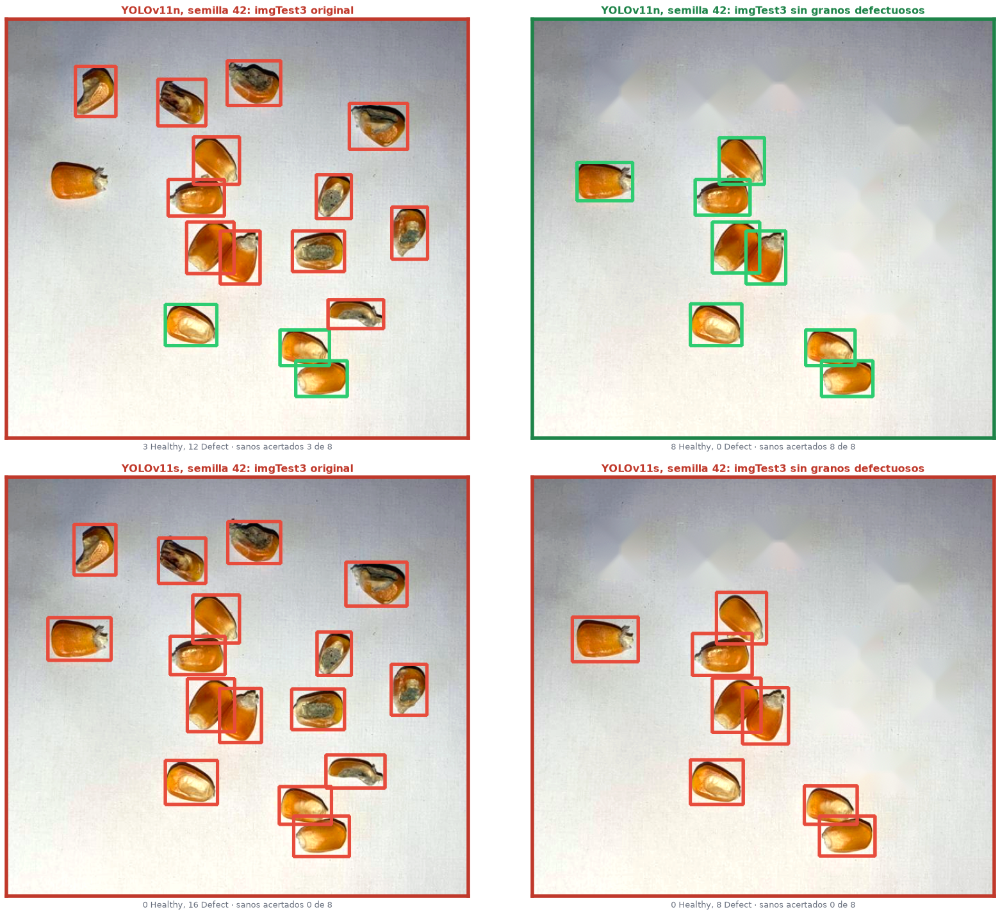

In [7]:
# imgTest3 original y sin granos defectuosos, con cada modelo (primera semilla). Borde verde: los 8 sanos acertados
fig, axes = plt.subplots(2, 2, figsize=(17, 14.5))
for fila, modelo in zip(axes, MODELOS):
    mod = dict(MODELOS[modelo])[S0]
    for ax, (nombre, x) in zip(fila, (('original', img3), ('sin granos defectuosos', VARIANTES_T3['sin defectuosos'][0]))):
        pre, ref = preparar(x, cajas3)
        r = mod.predict(pre, imgsz=E.IMGSZ, conf=CFG[modelo]['conf_conteo'], agnostic_nms=True, verbose=False)[0]
        pb, pc = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)
        pares, _ = E.emparejar(ref, pb)
        sanos_ok = sum(1 for g, q in pares.items() if cl3[g] == 0 and pc[q] == 0)
        vista = E.dibujar(E.dibujar(cv2.cvtColor(pre, cv2.COLOR_BGR2RGB), pb[pc == 0], E.CAJA_OK, 3), pb[pc == 1], E.CAJA_MAL, 3)
        (x1, y1), (x2, y2) = (ref[:, :2].min(0) - 60).clip(0).astype(int), (ref[:, 2:].max(0) + 60).astype(int)
        E.mostrar(ax, vista[y1:y2, x1:x2], f'{ETIQUETA[modelo]}, semilla {S0}: imgTest3 {nombre}',
                  f'{(pc == 0).sum()} Healthy, {(pc == 1).sum()} Defect · sanos acertados {sanos_ok} de {(cl3 == 0).sum()}',
                  estado='ok' if sanos_ok == (cl3 == 0).sum() else 'mal')
C.guardar(SALIDA, 'contexto_imgTest3.png')

**Escenas mezcladas en el entrenamiento.** Cuántas imágenes de `train` tienen granos de las dos clases, qué parte de los granos sanos está en ellas y, en esas imágenes, a qué distancia queda cada grano sano del defectuoso más cercano (en lados de grano). Se compara con las fotos propias.

In [8]:
def distancias(cajas, cl):
    # Distancia de cada grano sano al defectuoso más cercano, en lados de grano
    if not ((cl == 0).any() and (cl == 1).any()):
        return np.array([])
    c = np.stack([(cajas[:, 0] + cajas[:, 2]) / 2, (cajas[:, 1] + cajas[:, 3]) / 2], 1)
    lado = np.median(np.sqrt((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1])))
    d = np.linalg.norm(c[cl == 0][:, None] - c[cl == 1][None], axis=2).min(1)
    return d / lado

mezcla, dist, sanos_total = [], [], 0
for p in sorted((E.FINAL / 'train' / 'images').glob('*.jpg')):
    _, cajas, cl, _ = E.cargar(p.stem, 'train')
    mezcla.append(len(set(cl)) > 1); dist.extend(distancias(cajas, cl)); sanos_total += int((cl == 0).sum())
dist = np.array(dist)
filas = {'Data_final train': {'imágenes con las dos clases': f'{np.mean(mezcla):.0%} de {len(mezcla)}',
                              'sanos en escenas mezcladas': f'{len(dist) / sanos_total:.0%} de {sanos_total}',
                              'sanos a menos de 2 lados de un defectuoso': f'{(dist < 2).mean():.0%} de {len(dist)}',
                              'distancia mediana': f'{np.median(dist):.1f}'}}
for s in FOTOS_STEMS + ['imgMixta']:
    _, cajas, cl = REF[s]
    d = distancias(cajas, cl)
    filas[s] = {'imágenes con las dos clases': 'sí', 'sanos en escenas mezcladas': f'100% de {(cl == 0).sum()}',
                'sanos a menos de 2 lados de un defectuoso': f'{(d < 2).mean():.0%} de {len(d)}', 'distancia mediana': f'{np.median(d):.1f}'}
display(pd.DataFrame(filas).T)

,imágenes con las dos clases,sanos en escenas mezcladas,sanos a menos de 2 lados de un defectuoso,distancia mediana
Data_final train,8% de 344,4% de 5733,100% de 204,0.9
imgPrueba,sí,100% de 6,0% de 6,4.2
imgPrueba2,sí,100% de 6,0% de 6,4.3
imgTest3,sí,100% de 8,62% de 8,1.8
imgMixta,sí,100% de 7,71% de 7,1.9


## 4. Acercamiento del encuadre

Se compara cada foto completa con tres recortes alrededor del conjunto de cajas de referencia, con un margen del 50 %, 25 % y 10 % del lado mayor de esa región, limitado por los bordes de la foto. Cada recorte conserva todos los granos y pasa por el mismo preprocesamiento: al llevar su lado mayor a 1280 px, los granos se ven más grandes.

El acercamiento digital no reproduce una foto tomada más cerca: no añade detalle óptico, retira fondo y cambia las estadísticas de la normalización. Sirve para explorar la sensibilidad a la escala y al encuadre, no para atribuir una causa.

In [9]:
def encuadres_granos(img, cajas):
    # Recortes sin interpolación que conservan todas las cajas de referencia
    h, w = img.shape[:2]
    yield 'Completa', img, cajas.copy()
    minimo, maximo = cajas[:, :2].min(0), cajas[:, 2:].max(0)
    lado = float((maximo - minimo).max())
    for margen in (0.50, 0.25, 0.10):
        x1, y1 = np.maximum(np.floor(minimo - lado * margen), 0).astype(int)
        x2, y2 = np.minimum(np.ceil(maximo + lado * margen), [w, h]).astype(int)
        yield f'Margen {margen:.0%}', img[y1:y2, x1:x2].copy(), cajas - [x1, y1, x1, y1]

filas_encuadre, vistas_encuadre = [], {}
for foto in FOTOS_STEMS:
    img, cajas, clases = REF[foto]
    for nombre, recorte, referencia in encuadres_granos(img, cajas):
        for modelo in MODELOS:
            filas, pre, ref = evaluar(recorte, referencia, clases, modelo)
            vistas_encuadre[foto, nombre] = pre
            for f in filas:
                filas_encuadre.append({'foto': foto, 'encuadre': nombre, 'modelo': f['modelo'], 'semilla': f['semilla'],
                                       'lado mediano a 1280 (px)': rasgos(pre, ref)['lado del grano (px)'],
                                       'no detectados': f['no detectados'], 'predicciones sin pareja': f['detecciones'] - (len(clases) - f['no detectados']),
                                       'errores de clase': f['errores de clase'], 'sanos acertados': f['sanos acertados'],
                                       'defectuosos acertados': f['defectuosos acertados'], 'cajas': f['cajas'], 'clases': f['clases']})
encuadres = pd.DataFrame(filas_encuadre)
METRICAS_ENC = ['lado mediano a 1280 (px)', 'no detectados', 'predicciones sin pareja', 'errores de clase', 'sanos acertados', 'defectuosos acertados']
print('Media de las 3 semillas')
display(encuadres.groupby(['foto', 'encuadre', 'modelo'], sort=False)[METRICAS_ENC].mean().round(3))

Media de las 3 semillas


lado mediano a 1280 (px)  no detectados  \
foto       encuadre   modelo                                              
imgPrueba  Completa   YOLOv11n                    78.126          0.000   
                      YOLOv11s                    78.126          0.000   
           Margen 50% YOLOv11n                    95.176          0.000   
                      YOLOv11s                    95.176          0.000   
           Margen 25% YOLOv11n                   118.057          0.000   
                      YOLOv11s                   118.057          0.000   
           Margen 10% YOLOv11n                   147.571          0.000   
                      YOLOv11s                   147.571          0.000   
imgPrueba2 Completa   YOLOv11n                    88.612          0.000   
                      YOLOv11s                    88.612          0.000   
           Margen 50% YOLOv11n                    91.683          0.000   
                      YOLOv11s                    91.683          0.000   
           Margen 25% YOLOv11n                   109.033          0.000   
                      YOLOv11s                   109.033          0.000   
           Margen 10% YOLOv11n                   122.881          0.000   
                      YOLOv11s                   122.881          0.000   
imgTest3   Completa   YOLOv11n                    69.676          0.333   
                      YOLOv11s                    69.676          0.000   
           Margen 50% YOLOv11n                    80.492          0.333   
                      YOLOv11s                    80.492          0.333   
           Margen 25% YOLOv11n                   107.322          1.000   
                      YOLOv11s                   107.322          0.000   
           Margen 10% YOLOv11n                   134.112          1.000   
                      YOLOv11s                   134.112          0.000   

                                predicciones sin pareja  errores de clase  \
foto       encuadre   modelo                                                
imgPrueba  Completa   YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.000             1.333   
           Margen 50% YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.000             1.333   
           Margen 25% YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.000             0.667   
           Margen 10% YOLOv11n                    0.000             0.333   
                      YOLOv11s                    0.333             1.000   
imgPrueba2 Completa   YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.000             1.000   
           Margen 50% YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.000             0.667   
           Margen 25% YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.000             1.667   
           Margen 10% YOLOv11n                    0.000             0.000   
                      YOLOv11s                    0.333             0.000   
imgTest3   Completa   YOLOv11n                    0.000             6.000   
                      YOLOv11s                    0.000             7.000   
           Margen 50% YOLOv11n                    0.000             5.667   
                      YOLOv11s                    0.000             7.333   
           Margen 25% YOLOv11n                    0.000             3.333   
                      YOLOv11s                    0.000             6.333   
           Margen 10% YOLOv11n                    0.000             2.333   
                      YOLOv11s                    0.000             5.667   

                                sanos acertados  defectuosos acertados  
foto 

/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe1/comun.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


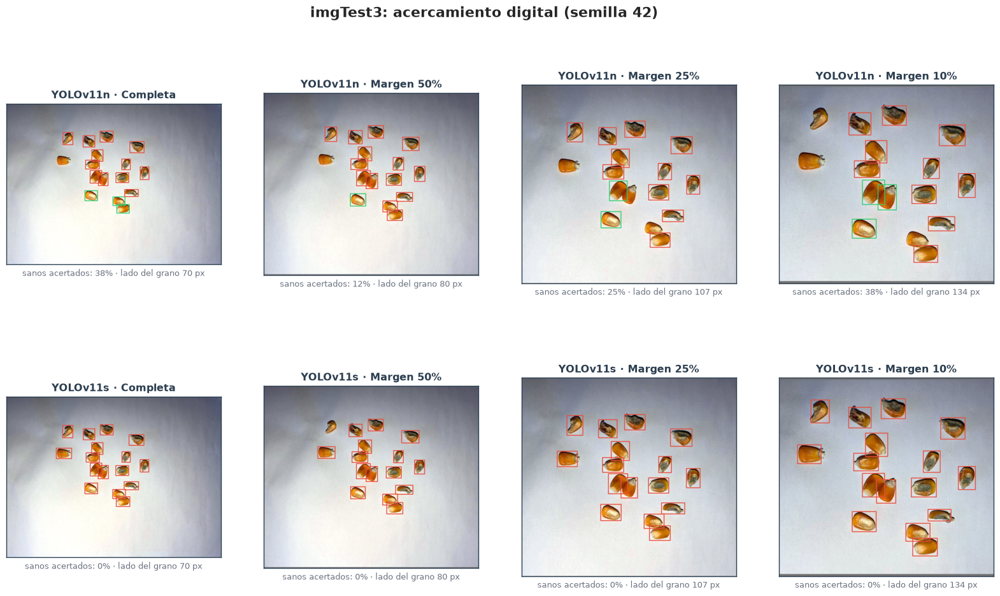

In [10]:
# imgTest3: mismo modelo y semilla en todos los encuadres de cada fila
orden_encuadres = ['Completa', 'Margen 50%', 'Margen 25%', 'Margen 10%']
fig, axes = plt.subplots(2, 4, figsize=(20, 10.5), squeeze=False, gridspec_kw={'hspace': 0.32})
for fila, modelo in zip(axes, ETIQUETA.values()):
    for ax, nombre in zip(fila, orden_encuadres):
        f = encuadres[(encuadres.foto == 'imgTest3') & (encuadres.encuadre == nombre) & (encuadres.modelo == modelo) & (encuadres.semilla == S0)].iloc[0]
        imagen = cv2.cvtColor(vistas_encuadre['imgTest3', nombre], cv2.COLOR_BGR2RGB)
        imagen = E.dibujar(E.dibujar(imagen, f['cajas'][f['clases'] == 0], E.CAJA_OK, 3), f['cajas'][f['clases'] == 1], E.CAJA_MAL, 3)
        E.mostrar(ax, imagen, f'{modelo} · {nombre}', f"sanos acertados: {f['sanos acertados']:.0%} · lado del grano {f['lado mediano a 1280 (px)']:.0f} px")
fig.suptitle(f'imgTest3: acercamiento digital (semilla {S0})', fontsize=16, fontweight='bold')
C.guardar(SALIDA, 'encuadres_imgTest3.png')

## 5. Escena de una sola clase frente a escena mezclada

`imgArrugados` (solo arrugados) e `imgMixta` (sanos grandes y arrugados pequeños mezclados) aíslan el efecto de mezclar clases con granos distintos a los de las otras fotos. Sobre `imgMixta` se repite la prueba de contexto: se borran por *inpainting* los sanos (queda una escena de solo arrugados) o los arrugados (queda una de solo sanos), y se evalúan los granos que quedan. Además de los aciertos, se mide la **fracción de la clase mayoritaria** entre las predicciones de cada corrida: 1.0 indica que el modelo asignó la misma clase a todos los granos de la escena.

In [11]:
imgM, cajasM, clM = REF['imgMixta']
ESCENAS = {'imgArrugados': (*REF['imgArrugados'], None),
           'imgMixta': (imgM, cajasM, clM, None),
           'imgMixta sin sanos': (borrar(imgM, cajasM[clM == 0]), cajasM, clM, 1),
           'imgMixta sin arrugados': (borrar(imgM, cajasM[clM == 1]), cajasM, clM, 0)}
filas, VISTA_ESC = [], {}
for nombre, (x, cajas, cl, sub) in ESCENAS.items():
    keep = np.ones(len(cl), bool) if sub is None else (cl == sub)
    for m in MODELOS:
        fs, pre, ref = evaluar(x, cajas[keep], cl[keep], m)
        VISTA_ESC[nombre] = (pre, preparar(x, cajas)[1])
        for f in fs:
            n = max(f['Healthy predichos'] + f['Defect predichos'], 1)
            filas.append({'escena': nombre, 'modelo': f['modelo'], 'semilla': f['semilla'], 'granos': int(keep.sum()),
                          'detecciones': f['detecciones'], 'Healthy predichos': f['Healthy predichos'], 'Defect predichos': f['Defect predichos'],
                          'sanos acertados': f['sanos acertados'], 'arrugados acertados': f['defectuosos acertados'],
                          'clase mayoritaria': max(f['Healthy predichos'], f['Defect predichos']) / n, 'cajas': f['cajas'], 'clases': f['clases']})
escenas = pd.DataFrame(filas)
cols = ['granos', 'detecciones', 'Healthy predichos', 'Defect predichos', 'sanos acertados', 'arrugados acertados', 'clase mayoritaria']
display(escenas.set_index(['escena', 'modelo', 'semilla'])[cols].round(2))
print('Media de las 3 semillas')
display(escenas.groupby(['escena', 'modelo'], sort=False)[['sanos acertados', 'arrugados acertados', 'clase mayoritaria']].mean().round(2))

granos  detecciones  \
escena                 modelo   semilla                        
imgArrugados           YOLOv11n 42            8            8   
                                7             8            8   
                                28            8            8   
                       YOLOv11s 42            8            8   
                                7             8            8   
                                28            8            8   
imgMixta               YOLOv11n 42           15           15   
                                7            15           13   
                                28           15           12   
                       YOLOv11s 42           15           15   
                                7            15           15   
                                28           15           15   
imgMixta sin sanos     YOLOv11n 42            8            8   
                                7             8            8   
                                28            8            8   
                       YOLOv11s 42            8            8   
                                7             8            8   
                                28            8            8   
imgMixta sin arrugados YOLOv11n 42            7            7   
                                7             7            7   
                                28            7            7   
                       YOLOv11s 42            7            7   
                                7             7            7   
                                28            7            7   

                                         Healthy predichos  Defect predichos  \
escena                 modelo   semilla                                        
imgArrugados           YOLOv11n 42                       0                 8   
                                7                        0                 8   
                                28                       0                 8   
                       YOLOv11s 42                       0                 8   
                                7                        0                 8   
                                28                       0                 8   
imgMixta               YOLOv11n 42                       0                15   
                                7                       11                 2   
                                28                      10                 2   
                       YOLOv11s 42                       0                15   
                                7                        0                15   
                                28                      15                 0   
imgMixta sin sanos     YOLOv11n 42                       0                 8   
                                7                        0                 8   
                                28                       0                 8   
                       YOLOv11s 42                       0                 8   
                                7                        0                 8   
                                28                       0                 8   
imgMixta sin arrugados YOLOv11n 42                       7                 0   
                                7                        7                 0   
                                28                       7                 0   
                       YOLOv11s 42                       6                 1   
                                7                        7                 0   
                                28                       7                 0   

                                         sanos acertados  arrugados acertados  \
escena                 modelo   semilla                                         
imgArrugados           YOLOv11n 42                   NaN                 1.00   
                                7                   

Media de las 3 semillas


sanos acertados  arrugados acertados  \
escena                 modelo                                           
imgArrugados           YOLOv11n              NaN                 1.00   
                       YOLOv11s              NaN                 1.00   
imgMixta               YOLOv11n             0.57                 0.42   
                       YOLOv11s             0.33                 0.67   
imgMixta sin sanos     YOLOv11n              NaN                 1.00   
                       YOLOv11s              NaN                 1.00   
imgMixta sin arrugados YOLOv11n             1.00                  NaN   
                       YOLOv11s             0.95                  NaN   

                                 clase mayoritaria  
escena                 modelo                       
imgArrugados           YOLOv11n               1.00  
                       YOLOv11s               1.00  
imgMixta               YOLOv11n               0.89  
                       YOLOv11s               1.00  
imgMixta sin sanos     YOLOv11n               1.00  
                       YOLOv11s               1.00  
imgMixta sin arrugados YOLOv11n               1.00  
                       YOLOv11s               0.95

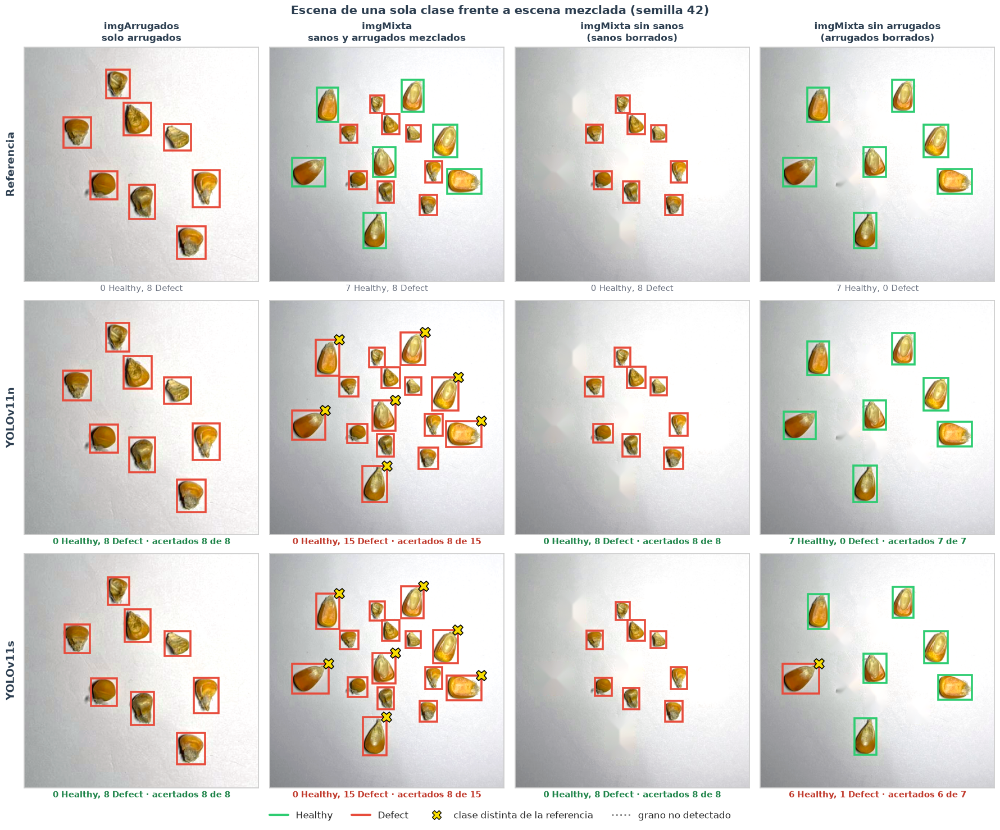

In [12]:
# Referencia y predicciones (primera semilla) en cada escena. Color de la caja: clase (verde Healthy, rojo Defect);
# la X amarilla marca una clase distinta de la referencia y la caja blanca punteada, un grano no detectado
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

TITULOS = {'imgArrugados': 'imgArrugados\nsolo arrugados', 'imgMixta': 'imgMixta\nsanos y arrugados mezclados',
           'imgMixta sin sanos': 'imgMixta sin sanos\n(sanos borrados)', 'imgMixta sin arrugados': 'imgMixta sin arrugados\n(arrugados borrados)'}
COLOR_CLASE = {0: np.array(E.CAJA_OK) / 255, 1: np.array(E.CAJA_MAL) / 255}

def encuadre_cuadrado(img, cajas, margen=0.12):
    (x0, y0), (x1, y1) = cajas[:, :2].min(0), cajas[:, 2:].max(0)
    lado = min(max(x1 - x0, y1 - y0) * (1 + 2 * margen), *img.shape[:2])
    cx = np.clip((x0 + x1) / 2, lado / 2, img.shape[1] - lado / 2)
    cy = np.clip((y0 + y1) / 2, lado / 2, img.shape[0] - lado / 2)
    return cx - lado / 2, cx + lado / 2, cy - lado / 2, cy + lado / 2

def panel(ax, x, limites, cajas, clases, errores=(), no_detectadas=()):
    ax.imshow(cv2.cvtColor(x, cv2.COLOR_BGR2RGB))
    for i, ((x1, y1, x2, y2), c) in enumerate(zip(cajas, clases)):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=COLOR_CLASE[c], lw=2.6))
        if i in errores:
            ax.plot(x2, y1, 'X', ms=13, mfc='#F7DC00', mec='black', mew=1.2)
    for x1, y1, x2, y2 in no_detectadas:
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec='white', lw=2, ls=':'))
    ax.set_xlim(limites[0], limites[1]); ax.set_ylim(limites[3], limites[2])
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axes = plt.subplots(3, 4, figsize=(18, 14.6))
for j, (nombre, (x, cajas, cl, sub)) in enumerate(ESCENAS.items()):
    keep = np.ones(len(cl), bool) if sub is None else (cl == sub)
    pre, ref_todas = VISTA_ESC[nombre]
    ref, cref = ref_todas[keep], cl[keep]
    limites = encuadre_cuadrado(pre, ref_todas)
    panel(axes[0, j], pre, limites, ref, cref)
    axes[0, j].set_title(TITULOS[nombre], fontsize=12.5, fontweight='bold', color=E.NEUTRO, pad=8)
    axes[0, j].set_xlabel(f'{(cref == 0).sum()} Healthy, {(cref == 1).sum()} Defect', fontsize=11, color=E.GRIS)
    for ax, m in zip(axes[1:, j], ETIQUETA.values()):
        f = escenas[(escenas.escena == nombre) & (escenas.modelo == m) & (escenas.semilla == S0)].iloc[0]
        pares, _ = E.emparejar(ref, f['cajas'])
        errores = {q for g, q in pares.items() if f['clases'][q] != cref[g]}
        no_det = [ref[g] for g in range(len(cref)) if g not in pares]
        panel(ax, pre, limites, f['cajas'], f['clases'], errores, no_det)
        aciertos = len(pares) - len(errores)
        ax.set_xlabel(f"{f['Healthy predichos']} Healthy, {f['Defect predichos']} Defect · acertados {aciertos} de {len(cref)}",
                      fontsize=11, color=E.OK if aciertos == len(cref) else E.MAL, fontweight='bold')
for ax, etiqueta in zip(axes[:, 0], ['Referencia', *ETIQUETA.values()]):
    ax.set_ylabel(etiqueta, fontsize=14, fontweight='bold', color=E.NEUTRO, labelpad=10)
leyenda = [Line2D([], [], color=COLOR_CLASE[0], lw=3, label='Healthy'), Line2D([], [], color=COLOR_CLASE[1], lw=3, label='Defect'),
           Line2D([], [], ls='', marker='X', ms=12, mfc='#F7DC00', mec='black', label='clase distinta de la referencia'),
           Line2D([], [], color='gray', lw=2, ls=':', label='grano no detectado')]
fig.legend(handles=leyenda, loc='lower center', ncol=4, fontsize=12, frameon=False, bbox_to_anchor=(0.5, -0.025))
fig.suptitle(f'Escena de una sola clase frente a escena mezclada (semilla {S0})', fontsize=15, fontweight='bold', color=E.NEUTRO)
C.guardar(SALIDA, 'escena_monoclase_mixta.png')